## INN Hotels Project



### Context

A significant number of hotel bookings are called-off due to cancellations or no-shows. The typical reasons for cancellations include change of plans, scheduling conflicts, etc. This is often made easier by the option to do so free of charge or preferably at a low cost which is beneficial to hotel guests but it is a less desirable and possibly revenue-diminishing factor for hotels to deal with. Such losses are particularly high on last-minute cancellations.

The new technologies involving online booking channels have dramatically changed customers’ booking possibilities and behavior. This adds a further dimension to the challenge of how hotels handle cancellations, which are no longer limited to traditional booking and guest characteristics.

The cancellation of bookings impact a hotel on various fronts:
* Loss of resources (revenue) when the hotel cannot resell the room.
* Additional costs of distribution channels by increasing commissions or paying for publicity to help sell these rooms.
* Lowering prices last minute, so the hotel can resell a room, resulting in reducing the profit margin.
* Human resources to make arrangements for the guests.

## Objective
The increasing number of cancellations calls for a Machine Learning based solution that can help in predicting which booking is likely to be canceled. INN Hotels Group has a chain of hotels in Portugal, they are facing problems with the high number of booking cancellations and have reached out to your firm for data-driven solutions. You as a data scientist have to analyze the data provided to find which factors have a high influence on booking cancellations, build a predictive model that can predict which booking is going to be canceled in advance, and help in formulating profitable policies for cancellations and refunds.

## Data Description
The data contains the different attributes of customers' booking details. The detailed data dictionary is given below.


**Data Dictionary**

* Booking_ID: unique identifier of each booking
* no_of_adults: Number of adults
* no_of_children: Number of Children
* no_of_weekend_nights: Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
* no_of_week_nights: Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel
* type_of_meal_plan: Type of meal plan booked by the customer:
    * Not Selected – No meal plan selected
    * Meal Plan 1 – Breakfast
    * Meal Plan 2 – Half board (breakfast and one other meal)
    * Meal Plan 3 – Full board (breakfast, lunch, and dinner)
* required_car_parking_space: Does the customer require a car parking space? (0 - No, 1- Yes)
* room_type_reserved: Type of room reserved by the customer. The values are ciphered (encoded) by INN Hotels.
* lead_time: Number of days between the date of booking and the arrival date
* arrival_year: Year of arrival date
* arrival_month: Month of arrival date
* arrival_date: Date of the month
* market_segment_type: Market segment designation.
* repeated_guest: Is the customer a repeated guest? (0 - No, 1- Yes)
* no_of_previous_cancellations: Number of previous bookings that were canceled by the customer prior to the current booking
* no_of_previous_bookings_not_canceled: Number of previous bookings not canceled by the customer prior to the current booking
* avg_price_per_room: Average price per day of the reservation; prices of the rooms are dynamic. (in euros)
* no_of_special_requests: Total number of special requests made by the customer (e.g. high floor, view from the room, etc)
* booking_status: Flag indicating if the booking was canceled or not.

## Functions

In [118]:
#FUNCTIONS
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mape_score(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

from statsmodels.stats.outliers_influence import variance_inflation_factor


def checking_vif(predictors):
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns

    # calculating VIF for each feature
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif

# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot


# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

## Importing necessary libraries and data

In [99]:
import pandas as pd
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant

from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score,roc_auc_score,roc_curve,auc, f1_score, classification_report,confusion_matrix,make_scorer


# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    make_scorer,
)

from sklearn.model_selection import GridSearchCV

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [73]:
data=pd.read_csv('/content/drive/MyDrive/GREAT LEARNING/4. SUPERVISED LEARNING CLASSIFICATION/Proyect/INNHotelsGroup.csv')

## Data Overview

- Observations
- Sanity checks

In [74]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [75]:
data.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [76]:
objetos=data.select_dtypes(include='object').columns.tolist()
objetos.remove('Booking_ID')

for i in objetos:
  print("-"*100)
  print(data[i].value_counts(normalize=True))

----------------------------------------------------------------------------------------------------
type_of_meal_plan
Meal Plan 1     0.767333
Not Selected    0.141420
Meal Plan 2     0.091110
Meal Plan 3     0.000138
Name: proportion, dtype: float64
----------------------------------------------------------------------------------------------------
room_type_reserved
Room_Type 1    0.775465
Room_Type 4    0.166975
Room_Type 6    0.026630
Room_Type 2    0.019076
Room_Type 5    0.007305
Room_Type 7    0.004356
Room_Type 3    0.000193
Name: proportion, dtype: float64
----------------------------------------------------------------------------------------------------
market_segment_type
Online           0.639945
Offline          0.290227
Corporate        0.055603
Complementary    0.010779
Aviation         0.003446
Name: proportion, dtype: float64
----------------------------------------------------------------------------------------------------
booking_status
Not_Canceled    0.672364
Ca

In [77]:
cambio={'Not_Canceled':0,'Canceled':1}
data['booking_status']=data['booking_status'].map(cambio)
data=data.drop(['arrival_year',	'arrival_date'],axis=1).copy()

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. What are the busiest months in the hotel?
2. Which market segment do most of the guests come from?
3. Hotel rates are dynamic and change according to demand and customer demographics. What are the differences in room prices in different market segments?
4. What percentage of bookings are canceled?
5. Repeating guests are the guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?
6. Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?

### The most busy months are August, September and October

<Axes: xlabel='arrival_month', ylabel='count'>

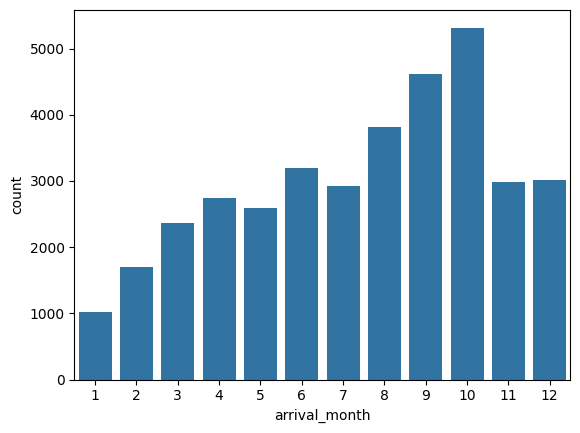

In [16]:
sns.countplot(data=data,x='arrival_month')

### Most guest come from the online segment

<ipython-input-2-04fa969a51ce>:164: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


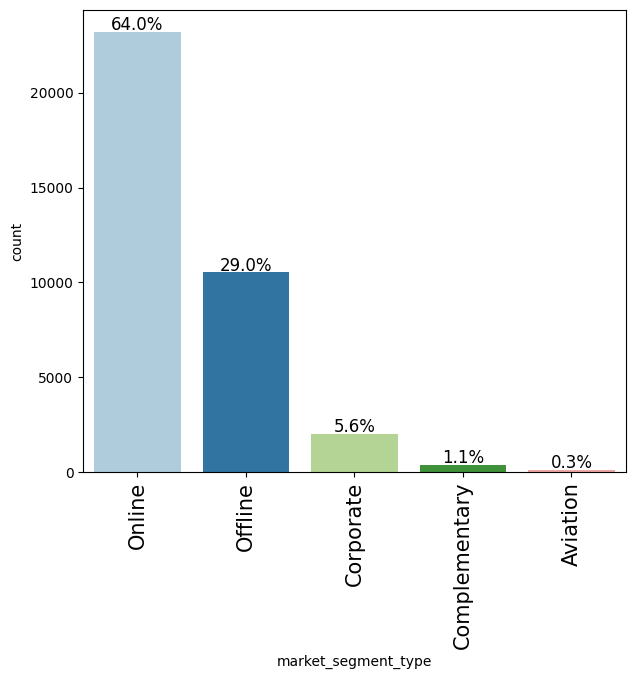

In [17]:
labeled_barplot(data,'market_segment_type',perc=True)

### We can see that Online prices tend to be higher, after that offline and finally Corporate. Complementary seems to have no cost.

In [18]:
data.groupby(['room_type_reserved','market_segment_type'])['avg_price_per_room'].mean()

room_type_reserved  market_segment_type
Room_Type 1         Aviation                94.166667
                    Complementary            4.064089
                    Corporate               80.458532
                    Offline                 91.532636
                    Online                 101.698294
Room_Type 2         Complementary            0.080000
                    Corporate               68.125000
                    Offline                 86.342982
                    Online                  90.916476
Room_Type 3         Complementary            0.000000
                    Corporate              110.000000
                    Offline                 97.500000
                    Online                 105.375000
Room_Type 4         Aviation               106.738462
                    Complementary            2.038462
                    Corporate               97.765354
                    Offline                 85.462463
                    Online                 131.934587
Room_Type 5         Complementary            6.823529
                    Corporate              119.572973
                    Offline                138.002099
                    Online                 135.987527
Room_Type 6         Complementary            0.000000
                    Corporate              114.690000
                    Offline                137.731739
                    Online                 186.291253
Room_Type 7         Complementary            0.025641
                    Corporate              127.000000
                    Offline                137.840000
                    Online                 212.808532
Name: avg_price_per_room, dtype: float64

### 32.8% of bookins are cancelled

<ipython-input-2-04fa969a51ce>:164: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


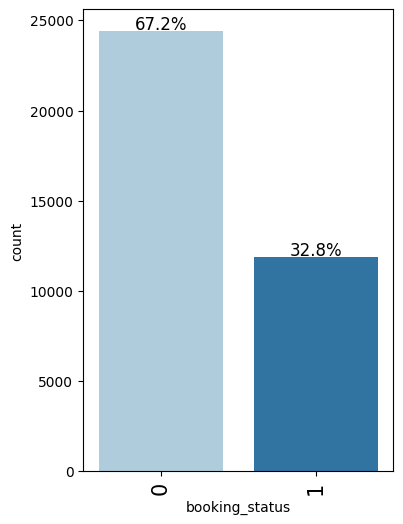

In [19]:
labeled_barplot(data,'booking_status',perc=True)

### Only 2% of repeating guests cancel their booking

<ipython-input-2-04fa969a51ce>:164: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


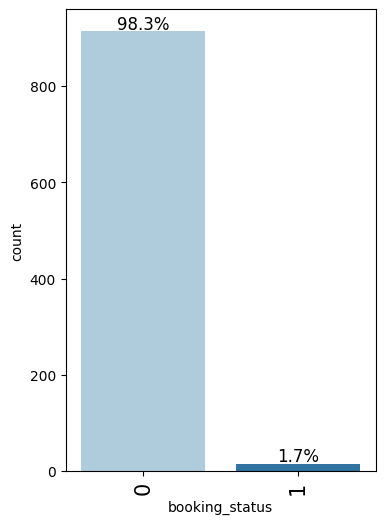

In [20]:
repeated=data[data['repeated_guest']==1].copy()
labeled_barplot(repeated,'booking_status',perc=True)

### The special requierements dont seem to affect the cancellation of the booking

<Axes: xlabel='no_of_special_requests', ylabel='count'>

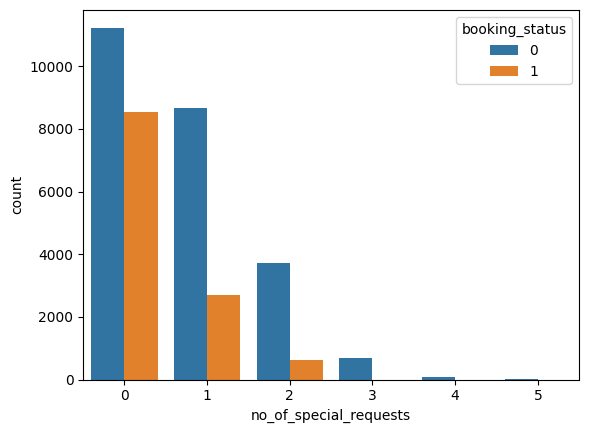

In [21]:
sns.countplot(data=data,x='no_of_special_requests',hue='booking_status')

## Univariate

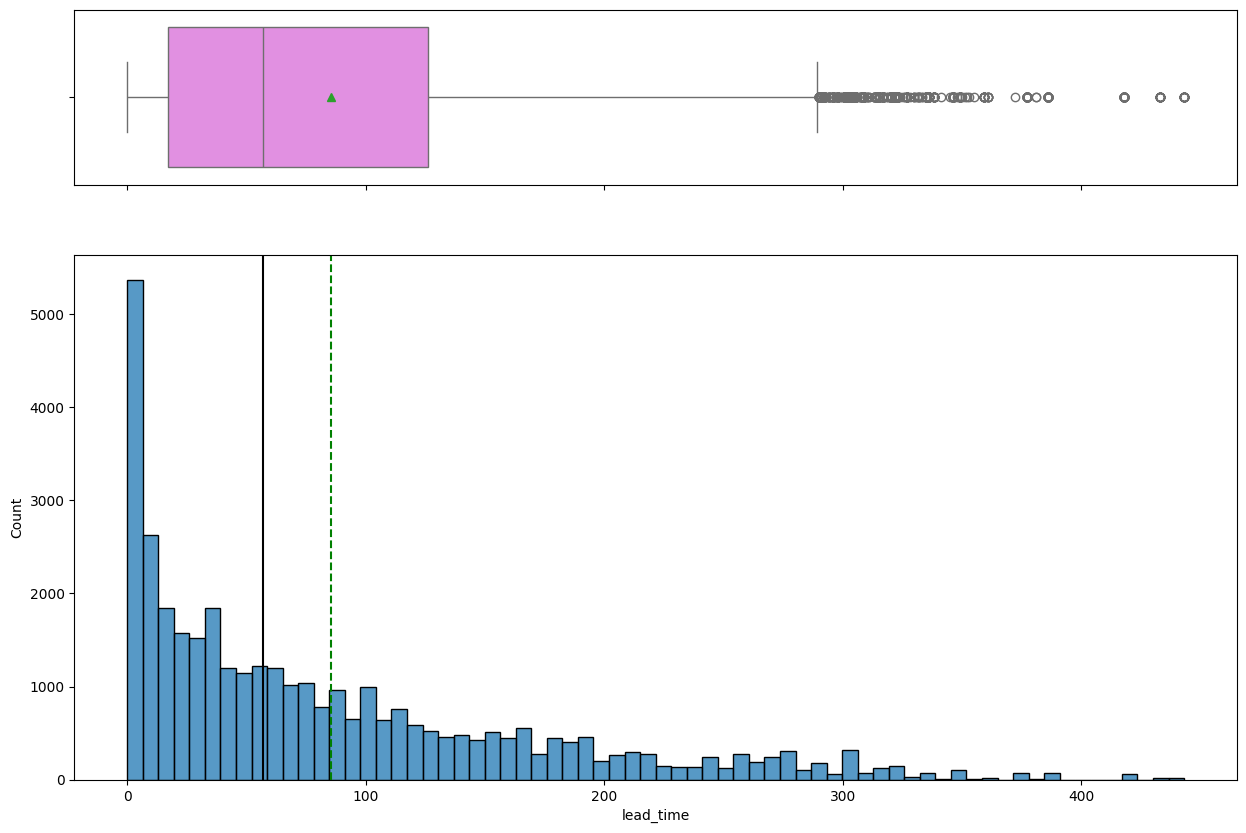

In [22]:
histogram_boxplot(data,'lead_time')

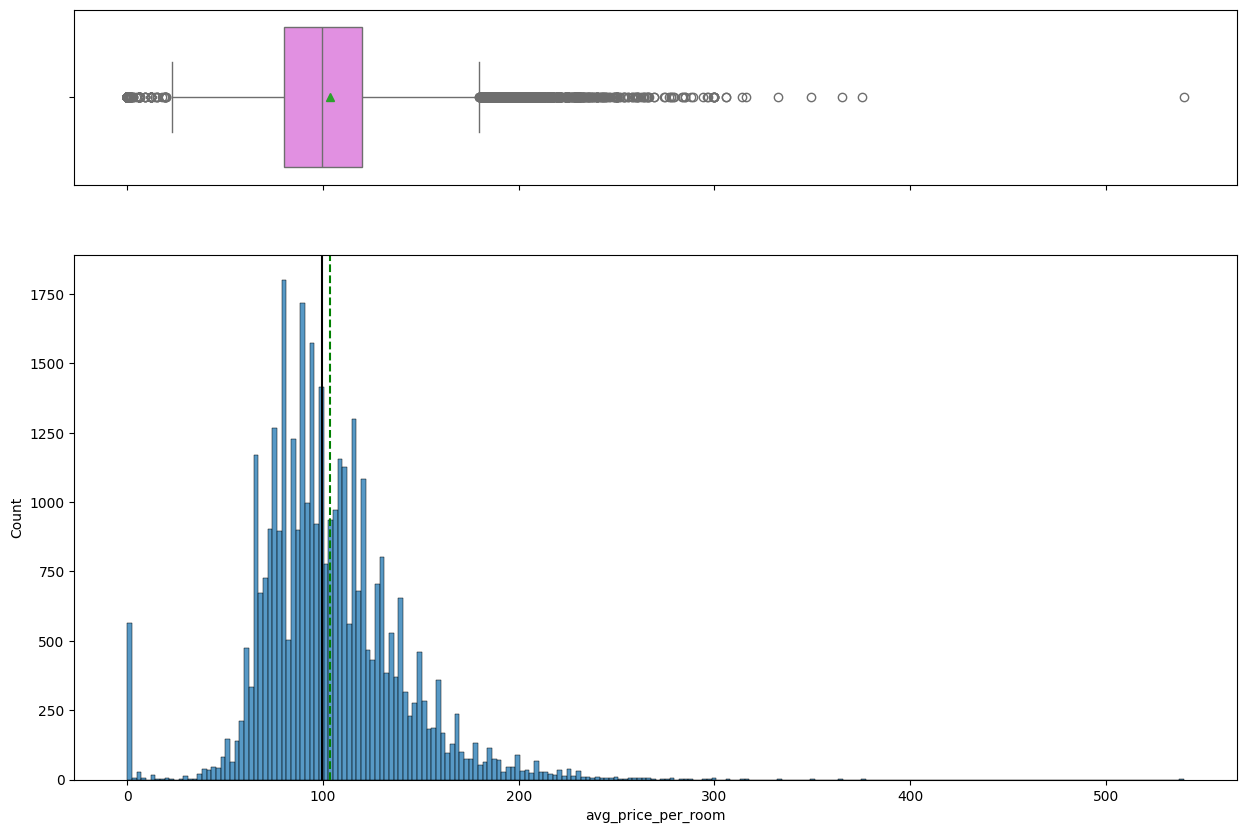

In [23]:
histogram_boxplot(data,'avg_price_per_room')

## Bivariate

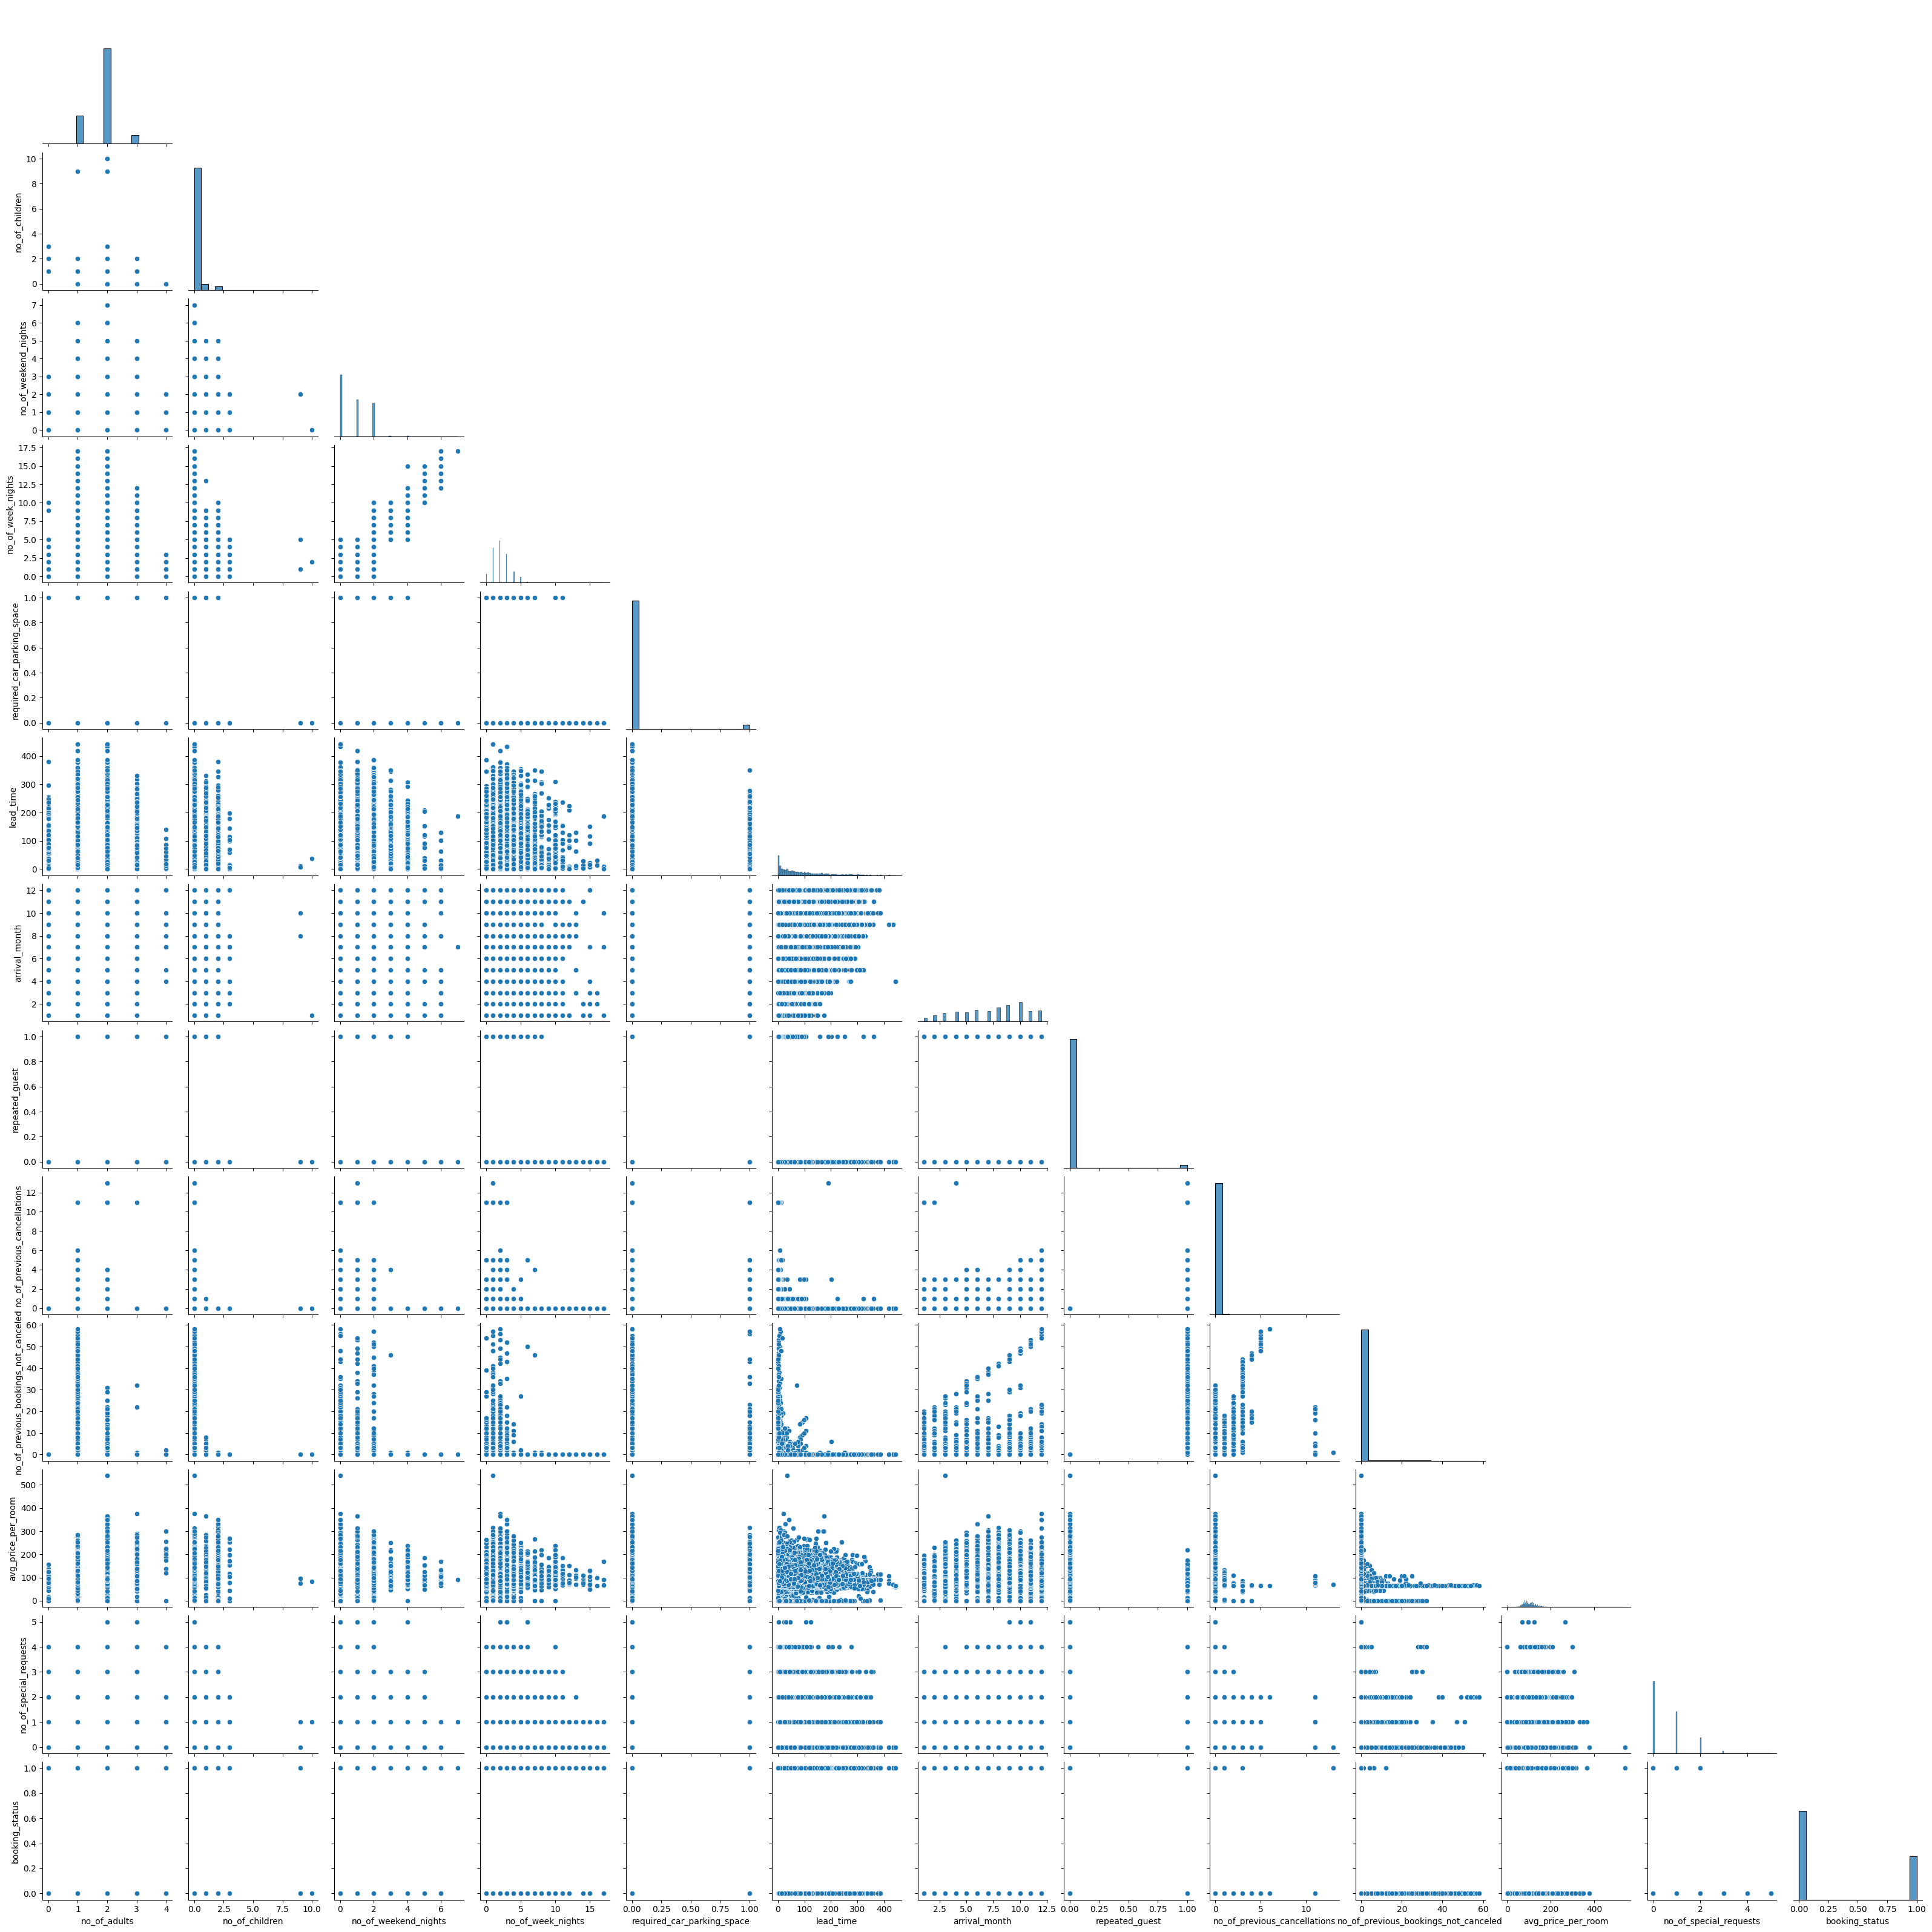

In [24]:
numbers=data.select_dtypes(include=['int64','float64']).columns.tolist()
numbers
sns.pairplot(data[numbers],corner=True)

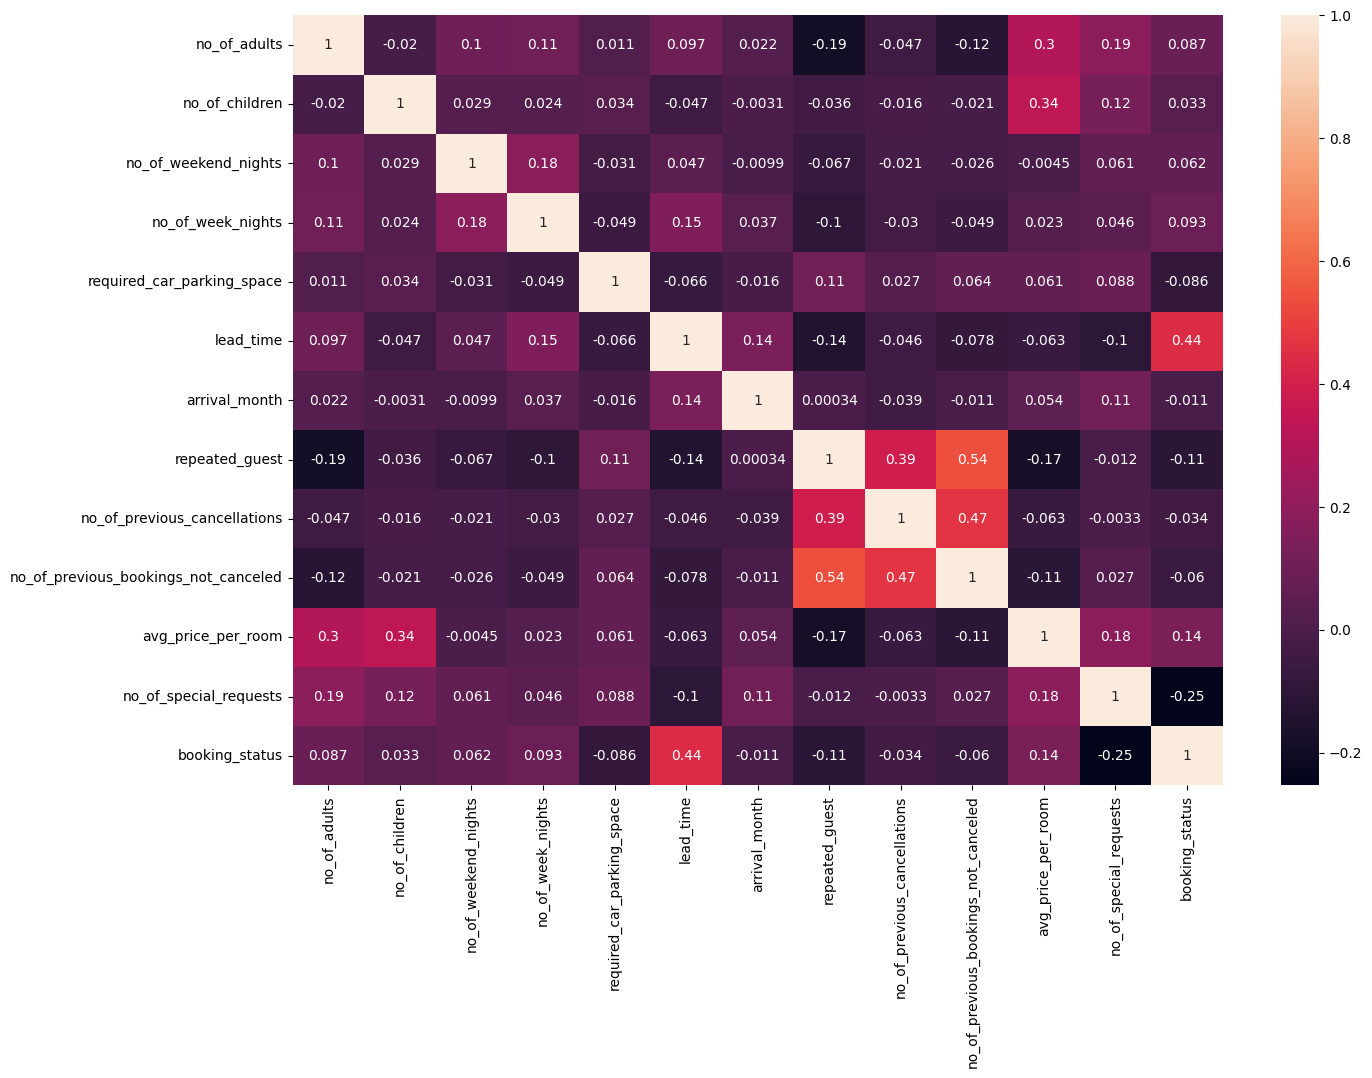

In [25]:
plt.figure(figsize=(15,10))
sns.heatmap(data[numbers].corr(),annot=True)
plt.show()

## Data Preprocessing

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [121]:
X=data.drop(['Booking_ID','booking_status'],axis=1).copy()
y=data['booking_status'].copy()

# adding a contstant to X variable
X = add_constant(X)

# creating dummies
X = pd.get_dummies(X, drop_first=True)

X=X.astype(float)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

## Checking Multicollinearity

- In order to make statistical inferences from a logistic regression model, it is important to ensure that there is no multicollinearity present in the data.

In [122]:
# let's check the VIF of the predictors
vif_series = pd.Series(
    [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])],
    index=X_train.columns,
    dtype=float,
)
print("VIF values: \n\n{}\n".format(vif_series))

VIF values: 

const                                   326.533761
no_of_adults                              1.341031
no_of_children                            2.005311
no_of_weekend_nights                      1.062890
no_of_week_nights                         1.091280
required_car_parking_space                1.037060
lead_time                                 1.243276
arrival_month                             1.049365
repeated_guest                            1.765563
no_of_previous_cancellations              1.369385
no_of_previous_bookings_not_canceled      1.613106
avg_price_per_room                        1.928107
no_of_special_requests                    1.243691
type_of_meal_plan_Meal Plan 2             1.198922
type_of_meal_plan_Meal Plan 3             1.005997
type_of_meal_plan_Not Selected            1.239456
room_type_reserved_Room_Type 2            1.090845
room_type_reserved_Room_Type 3            1.004845
room_type_reserved_Room_Type 4            1.352148
room_type_reserve

### WE remove the variable market_segment_type_Online

In [123]:
X_train=X_train.drop(['market_segment_type_Online'],axis=1).copy()

# let's check the VIF of the predictors
vif_series = pd.Series(
    [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])],
    index=X_train.columns,
    dtype=float,
)
print("VIF values: \n\n{}\n".format(vif_series))

VIF values: 

const                                   38.787736
no_of_adults                             1.323503
no_of_children                           2.004405
no_of_weekend_nights                     1.062073
no_of_week_nights                        1.090074
required_car_parking_space               1.037025
lead_time                                1.240525
arrival_month                            1.049299
repeated_guest                           1.763465
no_of_previous_cancellations             1.369185
no_of_previous_bookings_not_canceled     1.613039
avg_price_per_room                       1.928012
no_of_special_requests                   1.239374
type_of_meal_plan_Meal Plan 2            1.198858
type_of_meal_plan_Meal Plan 3            1.005997
type_of_meal_plan_Not Selected           1.238155
room_type_reserved_Room_Type 2           1.090641
room_type_reserved_Room_Type 3           1.004845
room_type_reserved_Room_Type 4           1.347540
room_type_reserved_Room_Type 5      

### Now there seems to be no multicollinearity

In [124]:
X_test=X_test.drop(['market_segment_type_Online'],axis=1).copy()

## Building a Logistic Regression model

In [125]:
# fitting the model on training set
logit = sm.Logit(y_train, X_train)
lg = logit.fit()

         Current function value: 0.425668
         Iterations: 35


/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## Model performance evaluation


Confusion Matrix:

     2229-1378
     749-6527

Acuraccy: 80.46%

Precision: 74.85%

Recall: 61.8%

Specificity: 89.71%

F1 Score: 67.7%



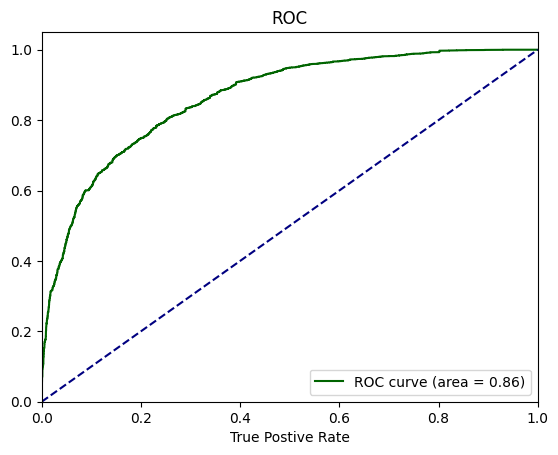

In [127]:
test_pred=lg.predict(X_test)
test_pred = np.round(test_pred)
y_prob=lg.predict(X_test)

fpr_test, tpr_test, _ =roc_curve(y_test, y_prob)
roc_auc =auc(fpr_test,tpr_test)

plt.plot(fpr_test,tpr_test,color="darkgreen",label="ROC curve (area = %0.2f)" % roc_auc,)

plt.plot([0,1],[0,1],color="navy",linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Postive Rate")
plt.xlabel("True Postive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.show


conf_matrix = confusion_matrix(y_test, test_pred)
TN, FP, FN, TP = conf_matrix.ravel()
print("")
print("Confusion Matrix:")
print("")
print(" "*5 + str(TP) + "-" + str(FN))
print(" "*5 + str(FP) + "-" + str(TN))
print("")

accuracy = round(accuracy_score(y_test, test_pred)*100,2)
print("Acuraccy: " + str(accuracy) + "%")
print("")

precision = round((TP / (TP + FP))*100,2)
print("Precision: " + str(precision) + "%")
print("")

recall = round((TP / (TP + FN))*100,2)
print("Recall: " + str(recall) + "%")
print("")

specificity = round((TN / (TN + FP))*100,2)
print("Specificity: " + str(specificity) + "%")
print("")

F1_Score=round(2*precision*recall/(precision+recall),2)
print("F1 Score: " + str(F1_Score) + "%")
print("")

## Final Model Summary

In [88]:
# summary of initial logistic regression model
print(lg.summary())

                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25367
Method:                           MLE   Df Model:                           24
Date:                Sun, 25 May 2025   Pseudo R-squ.:                  0.3257
Time:                        17:24:55   Log-Likelihood:                -10809.
converged:                      False   LL-Null:                       -16030.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                   -2.8730      0.109    -26.256      0.000      -3.087      -2.659
no_of_adults                             0.1095      

## Building a Decision Tree model

In [101]:
data2=data.copy()

meal={'Meal Plan 1':1,
      'Meal Plan 2':2,
      'Meal Plan 3':3,
      'Not Selected':-1}

room={'Room_Type 1':1,
      'Room_Type 2':2,
      'Room_Type 3':3,
      'Room_Type 4':4,
      'Room_Type 5':5,
      'Room_Type 6':6,
      'Room_Type 7':7}

market={'Online':1,
        'Offline':2,
        'Corporate':3,
        'Complementary':4,
        'Aviation':5}

data2['type_of_meal_plan']=data2['type_of_meal_plan'].map(meal)
data2['room_type_reserved']=data2['room_type_reserved'].map(room)
data2['market_segment_type']=data2['market_segment_type'].map(market)

In [131]:
X=data2.drop(['Booking_ID','booking_status'],axis=1).copy()
y=data2['booking_status'].copy()

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

dt= DecisionTreeClassifier(random_state=1)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

## Do we need to prune the tree?


Confusion Matrix:

     8147-131
     28-17086

Acuraccy: 99.37%

Precision: 99.66%

Recall: 98.42%

Specificity: 99.84%

F1 Score: 99.04%



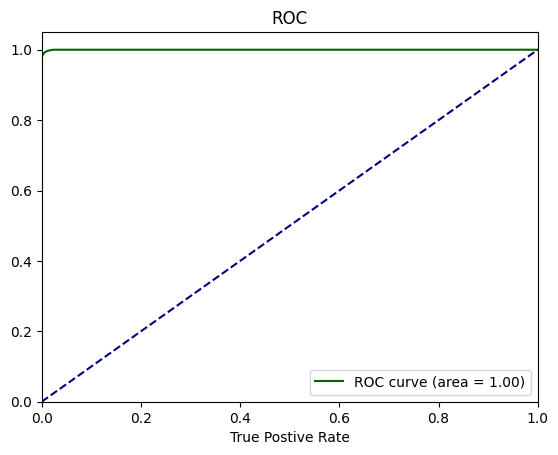

In [103]:
train_pred=dt.predict(X_train)
y_prob=dt.predict_proba(X_train)[:,1]

fpr_train, tpr_train, _ =roc_curve(y_train, y_prob)
roc_auc =auc(fpr_train,tpr_train)

plt.plot(fpr_train,tpr_train,color="darkgreen",label="ROC curve (area = %0.2f)" % roc_auc,)

plt.plot([0,1],[0,1],color="navy",linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Postive Rate")
plt.xlabel("True Postive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.show


conf_matrix = confusion_matrix(y_train, train_pred)
TN, FP, FN, TP = conf_matrix.ravel()
print("")
print("Confusion Matrix:")
print("")
print(" "*5 + str(TP) + "-" + str(FN))
print(" "*5 + str(FP) + "-" + str(TN))
print("")

accuracy = round(accuracy_score(y_train, train_pred)*100,2)
print("Acuraccy: " + str(accuracy) + "%")
print("")

precision = round((TP / (TP + FP))*100,2)
print("Precision: " + str(precision) + "%")
print("")

recall = round((TP / (TP + FN))*100,2)
print("Recall: " + str(recall) + "%")
print("")

specificity = round((TN / (TN + FP))*100,2)
print("Specificity: " + str(specificity) + "%")
print("")

F1_Score=round(2*precision*recall/(precision+recall),2)
print("F1 Score: " + str(F1_Score) + "%")
print("")


Confusion Matrix:

     2897-710
     753-6523

Acuraccy: 86.56%

Precision: 79.37%

Recall: 80.32%

Specificity: 89.65%

F1 Score: 79.84%



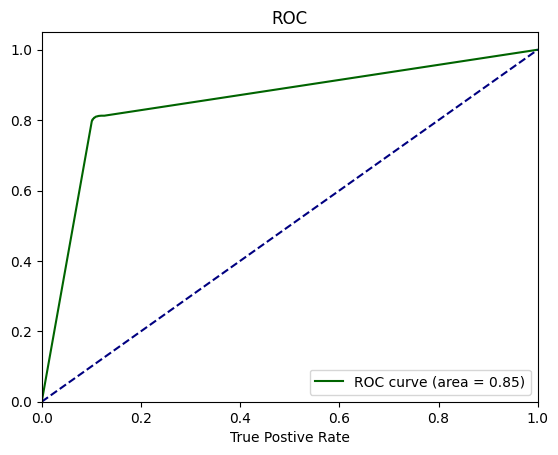

In [104]:
test_pred=dt.predict(X_test)
y_prob=dt.predict_proba(X_test)[:,1]

fpr_test, tpr_test, _ =roc_curve(y_test, y_prob)
roc_auc =auc(fpr_test,tpr_test)

plt.plot(fpr_test,tpr_test,color="darkgreen",label="ROC curve (area = %0.2f)" % roc_auc,)

plt.plot([0,1],[0,1],color="navy",linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Postive Rate")
plt.xlabel("True Postive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.show


conf_matrix = confusion_matrix(y_test, test_pred)
TN, FP, FN, TP = conf_matrix.ravel()
print("")
print("Confusion Matrix:")
print("")
print(" "*5 + str(TP) + "-" + str(FN))
print(" "*5 + str(FP) + "-" + str(TN))
print("")

accuracy = round(accuracy_score(y_test, test_pred)*100,2)
print("Acuraccy: " + str(accuracy) + "%")
print("")

precision = round((TP / (TP + FP))*100,2)
print("Precision: " + str(precision) + "%")
print("")

recall = round((TP / (TP + FN))*100,2)
print("Recall: " + str(recall) + "%")
print("")

specificity = round((TN / (TN + FP))*100,2)
print("Specificity: " + str(specificity) + "%")
print("")

F1_Score=round(2*precision*recall/(precision+recall),2)
print("F1 Score: " + str(F1_Score) + "%")
print("")

### We need to prune the tree beacuse it has almost a perfect performance on the training set. This means its overfitting and causing a drop on performance on the test set.

## Pre Prunning

In [105]:
# Grid of parameters to choose from
parameters = {
    "class_weight": [None, "balanced"],
    "max_depth": np.arange(2, 7, 2),
    "max_leaf_nodes": [50, 75, 150, 250],
    "min_samples_split": [10, 30, 50, 70],
}

# Type of scoring used to compare parameter combinations
acc_scorer = make_scorer(recall_score)

# Run the grid search
grid_obj = GridSearchCV(dt, parameters, scoring=acc_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dt_pre = grid_obj.best_estimator_

# Fit the best algorithm to the data.
dt_pre.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(2),
                       max_leaf_nodes=50, min_samples_split=10, random_state=1)


Confusion Matrix:

     3093-514
     3610-3666

Acuraccy: 62.11%

Precision: 46.14%

Recall: 85.75%

Specificity: 50.38%

F1 Score: 60.0%



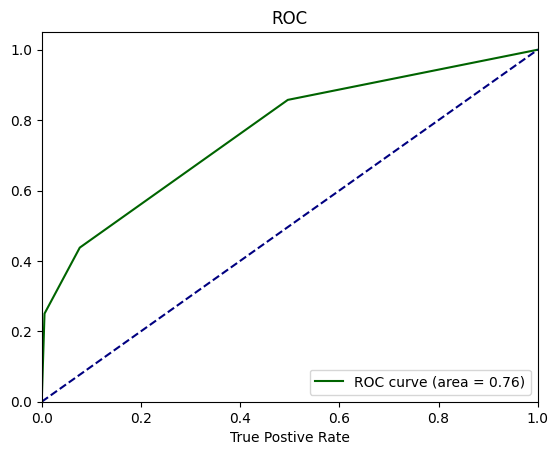

In [106]:
test_pred=dt_pre.predict(X_test)
y_prob=dt_pre.predict_proba(X_test)[:,1]

fpr_test, tpr_test, _ =roc_curve(y_test, y_prob)
roc_auc =auc(fpr_test,tpr_test)

plt.plot(fpr_test,tpr_test,color="darkgreen",label="ROC curve (area = %0.2f)" % roc_auc,)

plt.plot([0,1],[0,1],color="navy",linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Postive Rate")
plt.xlabel("True Postive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.show


conf_matrix = confusion_matrix(y_test, test_pred)
TN, FP, FN, TP = conf_matrix.ravel()
print("")
print("Confusion Matrix:")
print("")
print(" "*5 + str(TP) + "-" + str(FN))
print(" "*5 + str(FP) + "-" + str(TN))
print("")

accuracy = round(accuracy_score(y_test, test_pred)*100,2)
print("Acuraccy: " + str(accuracy) + "%")
print("")

precision = round((TP / (TP + FP))*100,2)
print("Precision: " + str(precision) + "%")
print("")

recall = round((TP / (TP + FN))*100,2)
print("Recall: " + str(recall) + "%")
print("")

specificity = round((TN / (TN + FP))*100,2)
print("Specificity: " + str(specificity) + "%")
print("")

F1_Score=round(2*precision*recall/(precision+recall),2)
print("F1 Score: " + str(F1_Score) + "%")
print("")

### Post Prunning

In [107]:
clf = DecisionTreeClassifier(random_state=1, class_weight="balanced")
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = abs(path.ccp_alphas), path.impurities

pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000e+00,0.009225
1,-1.084202e-19,0.009225
2,2.919250e-20,0.009225
3,2.919250e-20,0.009225
4,2.919250e-20,0.009225
...,...,...
1618,9.042021e-03,0.328673
1619,1.016896e-02,0.338842
1620,1.199329e-02,0.350835
1621,3.447635e-02,0.419788


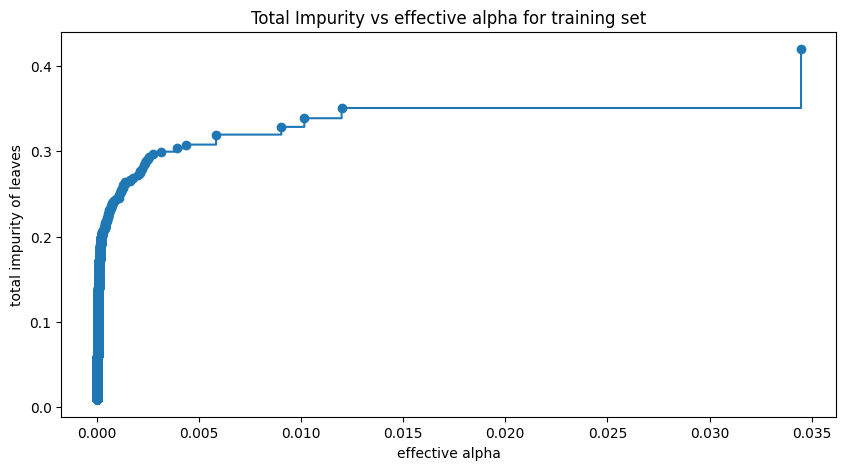

In [108]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

In [109]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        random_state=1, ccp_alpha=ccp_alpha, class_weight="balanced"
    )
    clf.fit(X_train, y_train)
    clfs.append(clf)
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.08021206599375391


In [110]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

In [111]:
recall_train = []
for clf in clfs:
    pred_train = clf.predict(X_train)
    values_train = recall_score(y_train, pred_train)
    recall_train.append(values_train)

recall_test = []
for clf in clfs:
    pred_test = clf.predict(X_test)
    values_test = recall_score(y_test, pred_test)
    recall_test.append(values_test)

train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]

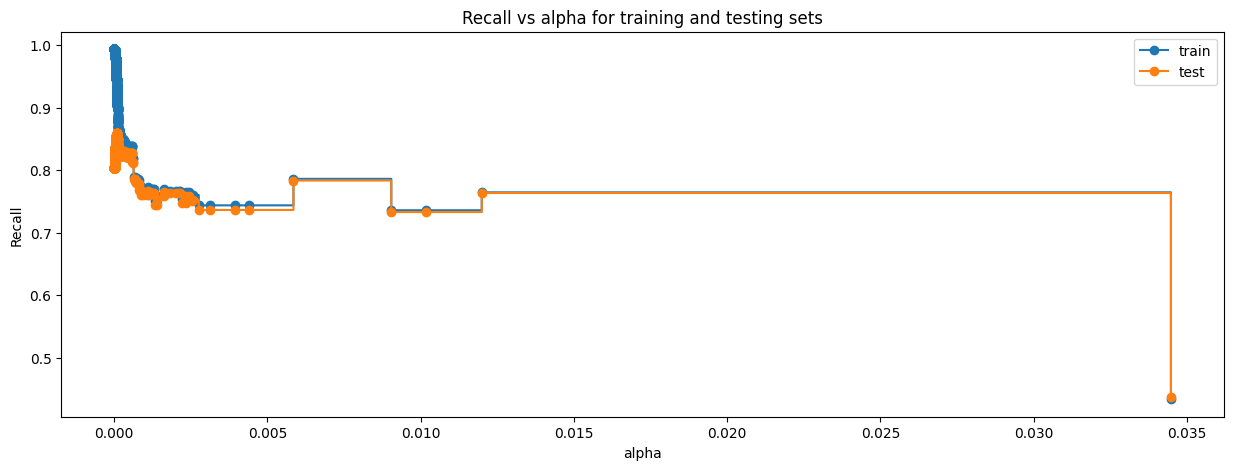

In [112]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(
    ccp_alphas, recall_train, marker="o", label="train", drawstyle="steps-post",
)
ax.plot(ccp_alphas, recall_test, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

In [113]:
# creating the model where we get highest train and test recall
index_best_model = np.argmax(recall_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(7.943893858524859e-05),
                       class_weight='balanced', random_state=1)



Confusion Matrix:

     3103-504
     976-6300

Acuraccy: 86.4%

Precision: 76.07%

Recall: 86.03%

Specificity: 86.59%

F1 Score: 80.74%



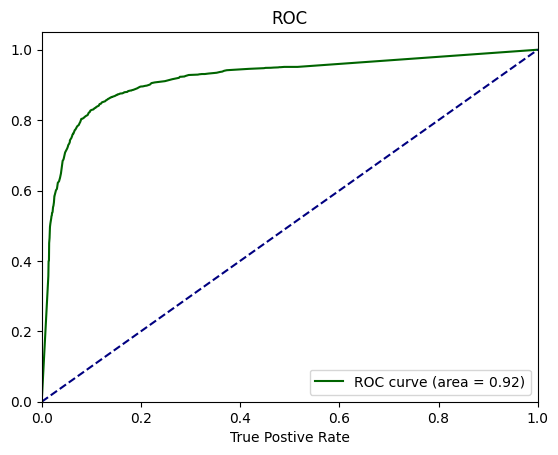

In [132]:
test_pred=best_model.predict(X_test)
y_prob=best_model.predict_proba(X_test)[:,1]

fpr_test, tpr_test, _ =roc_curve(y_test, y_prob)
roc_auc =auc(fpr_test,tpr_test)

plt.plot(fpr_test,tpr_test,color="darkgreen",label="ROC curve (area = %0.2f)" % roc_auc,)

plt.plot([0,1],[0,1],color="navy",linestyle="--")
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Postive Rate")
plt.xlabel("True Postive Rate")
plt.title("ROC")
plt.legend(loc="lower right")
plt.show


conf_matrix = confusion_matrix(y_test, test_pred)
TN, FP, FN, TP = conf_matrix.ravel()
print("")
print("Confusion Matrix:")
print("")
print(" "*5 + str(TP) + "-" + str(FN))
print(" "*5 + str(FP) + "-" + str(TN))
print("")

accuracy = round(accuracy_score(y_test, test_pred)*100,2)
print("Acuraccy: " + str(accuracy) + "%")
print("")

precision = round((TP / (TP + FP))*100,2)
print("Precision: " + str(precision) + "%")
print("")

recall = round((TP / (TP + FN))*100,2)
print("Recall: " + str(recall) + "%")
print("")

specificity = round((TN / (TN + FP))*100,2)
print("Specificity: " + str(specificity) + "%")
print("")

F1_Score=round(2*precision*recall/(precision+recall),2)
print("F1 Score: " + str(F1_Score) + "%")
print("")

## Model Performance Comparison and Conclusions


      Accuracy:
          Logistic Regression: 80.46,
          Decision Tree Free: 86.56,
          Decision Tree Pre-Pruning: 62.11,
          Decision Tree Post-Pruning: 86.4

      Precision:
          Logistic Regression: 74.85,
          Decision Tree Free: 79.37,
          Decision Tree Pre-Pruning: 46.14,
          Decision Tree Post-Pruning: 76.07

      Recall:
          Logistic Regression: 61.8,
          Decision Tree Free: 80.32,
          Decision Tree Pre-Pruning: 85.75,
          Decision Tree Post-Pruning: 86.03

      F1 Score:
          Logistic Regression: 67.7,
          Decision Tree Free: 79.84,
          Decision Tree Pre-Pruning: 60.0,
          Decision Tree Post-Pruning: 80.74


The hotel loses money when a reservation is canceled and this was not predicted in time. Therefore, Type II Error (False Negative) is the most costly: Predicting that a reservation won’t be canceled when it actually is.

The goal is to maximize Recall: catch as many true cancellations as possible. However, we also care about Precision, to avoid too many false alarms (False Positives).

The Decision Tree with post-pruning is the most suitable model for this business case. It offers the best balance between capturing cancellations and avoiding false positives, making it a reliable model for operational decisions like overbooking or reservation confirmations.

In [136]:
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_model.feature_importances_
})

# Ordenamos de mayor a menor importancia
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

print(feature_importances)

                                 Feature  Importance
7                              lead_time    0.392028
13                    avg_price_per_room    0.155689
9                    market_segment_type    0.133471
14                no_of_special_requests    0.113819
8                          arrival_month    0.070128
2                   no_of_weekend_nights    0.034505
3                      no_of_week_nights    0.034452
0                           no_of_adults    0.032493
5             required_car_parking_space    0.010258
4                      type_of_meal_plan    0.009500
6                     room_type_reserved    0.008579
1                         no_of_children    0.003267
10                        repeated_guest    0.001154
11          no_of_previous_cancellations    0.000657
12  no_of_previous_bookings_not_canceled    0.000000


## Actionable Insights and Recommendations

- What profitable policies for cancellations and refunds can the hotel adopt?
- What other recommedations would you suggest to the hotel?

### Profitable Policies for Cancellations and Refunds
#### 1. Dynamic Refund Policies Based on Risk

High-risk bookings (long lead time, high price, OTA segment): Apply stricter refund policies (e.g., partial refund only or full refund until 7 days before).

Low-risk bookings (short lead time, repeated guests, direct channel):Allow flexible cancellation, which improves customer loyalty.

#### 2. Deposit Requirements
For high-risk bookings, require a deposit upfront to discourage casual bookings.Particularly useful for expensive rooms or long stays.

#### 3. Overbooking Strategy Using the Model
Use the cancellation prediction model to intelligently overbook rooms with minimal risk.

#### 4. Early Reconfirmation Campaigns
For reservations with long lead_time, send automated reconfirmation emails or SMS a few weeks before check-in.Guests who dont respond can be flagged as higher risk. Consider offering a small benefit for confirmation, such as early check-in or room upgrade.

#### 5. Market Segment Optimization
Identify segments with high cancellation rates. Consider incentivizing direct bookings with lower cancellation likelihood and lower commission costs.
